# BankCustomerChurnANN


In [1]:
# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
# Step 1: Download the Bank Customer Churn dataset
import urllib.request

url = "https://raw.githubusercontent.com/GlebTsy/bank-customer-churn-modeling/master/Churn.csv"
urllib.request.urlretrieve(url, "Churn_Modelling.csv")

print("Dataset downloaded successfully!")
# Step 2: Load the bank customer dataset
df = pd.read_csv("Churn_Modelling.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df["Exited"].value_counts())

Dataset downloaded successfully!
Dataset shape: (10000, 14)
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0     2.0       0.00              1          1               1   
1     1.0   83807.86              1          0               1   
2     8.0  159660.80              3          1               0   
3     1.0       0.00              2          0               0   
4     2.0  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        11

In [3]:
# Step 3: Remove identifier columns and separate features and target
X = df.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])
y = df["Exited"]

# Convert categorical features into numeric values
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10000, 11)
Target shape: (10000,)


In [4]:
# Step 4: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 8000
Testing samples: 2000


In [5]:
# Step 5: Normalize features between 0 and 1
scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data normalized successfully.")

Training data normalized successfully.


In [6]:
# Step 6: Build the Artificial Neural Network
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:

# Step 7: Train ANN with class weights
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = dict(zip(classes, weights))

early_stop = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    class_weight=class_weights,
    verbose=1
)


Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.7508 - loss: 0.6956 - val_accuracy: 0.2000 - val_loss: 0.6934
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.2047 - loss: 0.6944 - val_accuracy: 0.2000 - val_loss: 0.6933
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2047 - loss: 0.6944 - val_accuracy: 0.2000 - val_loss: 0.6938
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6187 - loss: 0.6944 - val_accuracy: 0.2000 - val_loss: 0.6934
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.2047 - loss: 0.6944 - val_accuracy: 0.2000 - val_loss: 0.6939
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.2047 - loss: 0.6944 - val_accuracy: 0.2000 - val_loss: 0.6952
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2738 - loss: 0.6944 - val_accuracy: 0.2000 - val_loss: 0.6934


In [8]:
# Step 8: Evaluate ANN on test data
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", round(loss, 4))
print("Test Accuracy:", round(accuracy * 100, 2), "%")

Test Loss: 0.6933
Test Accuracy: 20.35 %


In [9]:

# Step 9: Predict and evaluate customer churn
from sklearn.metrics import classification_report

y_prob = model.predict(X_test, verbose=0)
y_pred = (y_prob >= 0.5).astype(int).ravel()

print("Actual values:   ", y_test.iloc[:10].to_list())
print("Predicted values:", y_pred[:10])
print("\nClassification Report:\n",
      classification_report(y_test, y_pred, zero_division=0))


Actual values:    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Predicted values: [1 1 1 1 1 1 1 1 1 1]

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00      1593
           1       0.20      1.00      0.34       407

    accuracy                           0.20      2000
   macro avg       0.10      0.50      0.17      2000
weighted avg       0.04      0.20      0.07      2000



Confusion Matrix:
 [[   0 1593]
 [   0  407]]


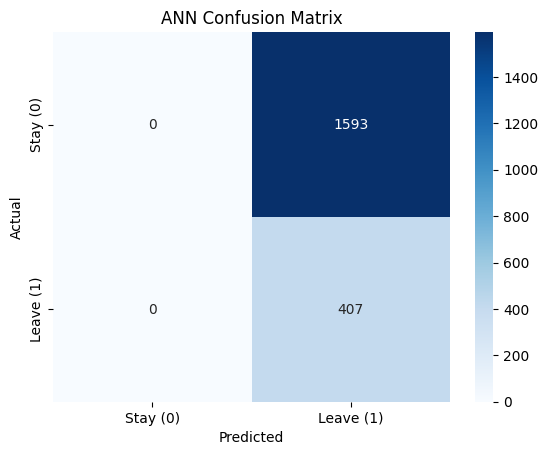

In [10]:
# Step 10: Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:\n", cm)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Stay (0)", "Leave (1)"],
    yticklabels=["Stay (0)", "Leave (1)"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ANN Confusion Matrix")
plt.show()

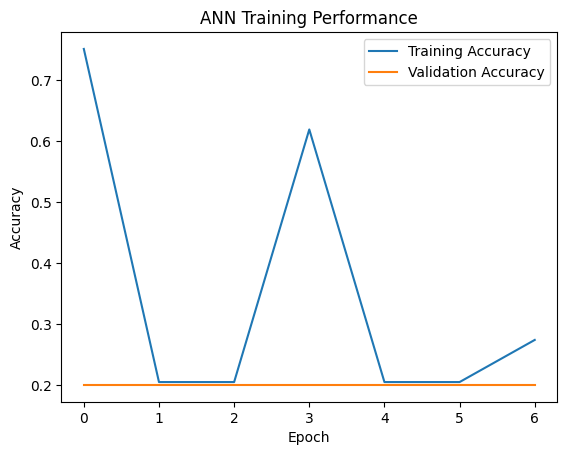

In [11]:
# Step 11: Plot training and validation accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN Training Performance")
plt.legend()
plt.show()